::: {.sb-lesson-links}
[Exercises →](../exercises/electricity.ipynb)
[Quiz →](../quiz/quiz.qmd)
[All files of this section (zip)](../../files/08-time-series.zip)
:::

::: {.sb-downloads}
[Download this notebook](../downloads/lesson-prophet.ipynb){download="lesson-prophet.ipynb"}  
Data: [apple_stock.csv](../downloads/data/apple_stock.csv){download="apple_stock.csv"} · [microsoft_stock.csv](../downloads/data/microsoft_stock.csv){download="microsoft_stock.csv"}

Put the data files in a folder named `data` next to the notebook.
:::

## What you'll learn in this course 

With Machine Learning comes very specific data: Time series. That type of data should be treated very specifically. In this course, you'll learn:

* How to handle Time Series data 
* What are the common models 
* Create time series forecasting with Prophet 
* The model behind Prophet
* Include seasonality, holidays and other specific events in your forecast

## What are Time Series 🤔🤔

Simply put time series are data based on time. For example you can have:

* Sales forecast
* Spread of a virus over time 
* Stock prices prediction
* Weather forecasting 
* ...


## Models associated with Time Series 📈📈

When you are doing time series forecasting. You can use plenty different types of models. Among the most popular are: 

* Moving averages
* Auto-correlations 
* Autoregressive Integrated Moving Average (ARIMA)

## Facebook Prophet 🔮🔮

Prophet is an open source project used for Time Series Forecasting. Basically, Prophet rely on three components: 

$y(t) = g(t) + s(t) + h(t) + \varepsilon_{t}$

where 

$y(t)$ - forecast 

$g(t)$ - trend 

$s(t)$ - seasonality or periodical changes

$h(t)$ - holidays 

$\varepsilon_{t}$ - Noise 

We'll review each of these components in this course. 




## Install Prophet

Prophet is a Python library: install it with `pip install prophet`.

## Example with Finance Data 

For the rest of the course, we'll be using daily stock prices (from Yahoo Finance), saved in the data folder: `../data/apple_stock.csv` and `../data/microsoft_stock.csv`

In [ ]:
import pandas as pd
import prophet

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
# colour palette of the course
pio.templates["course"] = go.layout.Template(
    layout_colorway=["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"]
)
pio.templates.default = "plotly_white+course"

import logging
logging.getLogger("cmdstanpy").disabled = True  # hide the messages of Prophet's optimizer

In [ ]:
# Import the plotting library
import matplotlib.pyplot as plt

# Get the data of the stock AAPL
data = pd.read_csv("../data/apple_stock.csv", index_col="Date", parse_dates=True).loc["2017-01-01":"2020-01-01"]

# Plot the close price of the AAPL
fig = px.line(x = data['Close'].index, y = data['Close'])
fig.show()

In [ ]:
data

,Open,High,Low,Close,Volume
Date,,,,,
2017-01-03,26.5975,26.7193,26.3587,26.6779,115127600
2017-01-04,26.6090,26.7606,26.5861,26.6481,84472400
2017-01-05,26.6251,26.8410,26.5998,26.7836,88774400
2017-01-06,26.8226,27.1396,26.7514,27.0822,127007600
2017-01-09,27.0914,27.4313,27.0891,27.3302,134247600
...,...,...,...,...,...
2019-12-24,68.4513,68.4994,68.0258,68.3504,48478800
2019-12-26,68.4826,69.7233,68.4538,69.7065,93121200
2019-12-27,69.9974,70.6827,69.2761,69.6800,146266000


Our goal is going to predict future stock prices of Apple Inc.

## Forecasting 🧙‍♂️🧙‍♂️

The best thing about Prophet is that it follows the same principles as `sklearn`. Making it very easy to use. Let's show a quick example. 

First Prophet needs to receive a DataFrame with the: 

* `ds` column corresponding to the time in YYYY-MM-DD format 
* `y` column corresponding to your target variable 

In [ ]:
# Format a dataframe for Prophet where you need to have a 'ds' column for time and 'y' column for prediction 

p_df = pd.DataFrame({
    "ds":data.index,
    "y": data["Open"].values
}).reset_index(drop=True)


p_df.head()

,ds,y
0,2017-01-03,26.5975
1,2017-01-04,26.6090
2,2017-01-05,26.6251
3,2017-01-06,26.8226
4,2017-01-09,27.0914


Next, we'll instanciate a `Prophet` instance and `fit` it to our DataFrame 

In [ ]:
from prophet import Prophet

m = Prophet()
m.fit(p_df)

Now we'll create predictions for future dates with Prophet

In [ ]:
future = m.make_future_dataframe(periods=100) # We create 100 more days
future

,ds
0,2017-01-03
1,2017-01-04
2,2017-01-05
3,2017-01-06
4,2017-01-09
...,...
849,2020-04-05
850,2020-04-06
851,2020-04-07
852,2020-04-08


Let's make our predictions 

In [ ]:
forecast = m.predict(future)
forecast.tail()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,weekly,weekly_lower,weekly_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
849,2020-04-05,75.233405,74.020167,84.411230,70.363979,80.324608,3.853585,3.853585,3.853585,0.684307,0.684307,0.684307,3.169278,3.169278,3.169278,0.0,0.0,0.0,79.086990
850,2020-04-06,75.325878,72.726167,83.578475,70.381240,80.462901,2.729788,2.729788,2.729788,-0.378610,-0.378610,-0.378610,3.108398,3.108398,3.108398,0.0,0.0,0.0,78.055666
851,2020-04-07,75.418350,72.850140,83.812803,70.389251,80.586912,2.742906,2.742906,2.742906,-0.299562,-0.299562,-0.299562,3.042468,3.042468,3.042468,0.0,0.0,0.0,78.161256
852,2020-04-08,75.510822,72.828022,83.603565,70.397262,80.747035,2.742037,2.742037,2.742037,-0.230346,-0.230346,-0.230346,2.972383,2.972383,2.972383,0.0,0.0,0.0,78.252859
853,2020-04-09,75.603294,72.730717,84.405455,70.405274,80.952055,2.677026,2.677026,2.677026,-0.222142,-0.222142,-0.222142,2.899168,2.899168,2.899168,0.0,0.0,0.0,78.280320


And finally plot the results with plotly

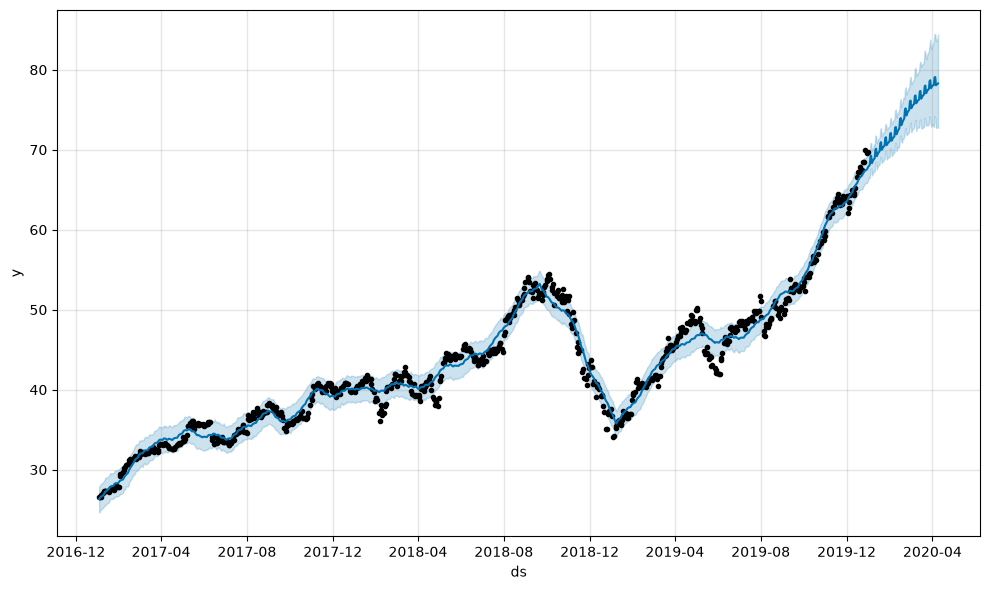

In [ ]:
fig = m.plot(forecast)

You can also plot each components of your trend. So that you can see the seasonality.

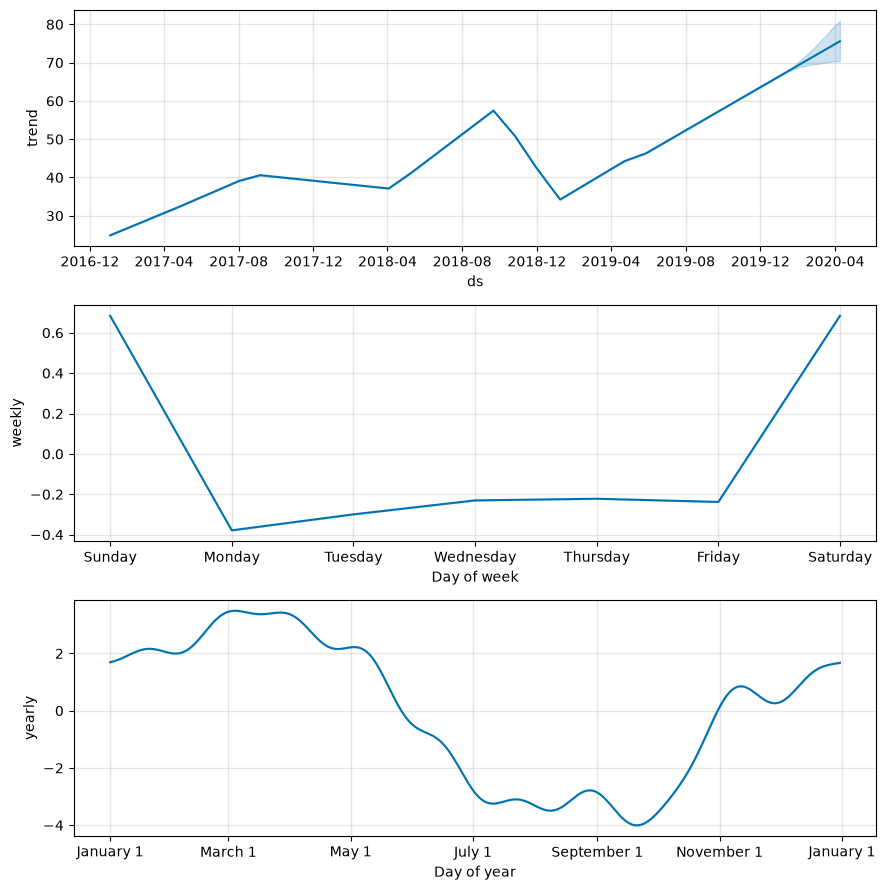

In [ ]:
fig2 = m.plot_components(forecast)

## Handle Seasonality

One very cool feature that you can use with Prophet is to add seasonality. For example, you can add country holidays. 

In [ ]:
m = Prophet()
m.add_country_holidays(country_name='US')
m.fit(p_df)

Check all the added holidays

In [ ]:
m.train_holiday_names

0                 New Year's Day
1      New Year's Day (observed)
2                   Memorial Day
3               Independence Day
4                      Labor Day
5               Thanksgiving Day
6                  Christmas Day
7     Martin Luther King Jr. Day
8          Washington's Birthday
9                   Columbus Day
10                  Veterans Day
11       Veterans Day (observed)
dtype: str

Check now its impact on your forecast 

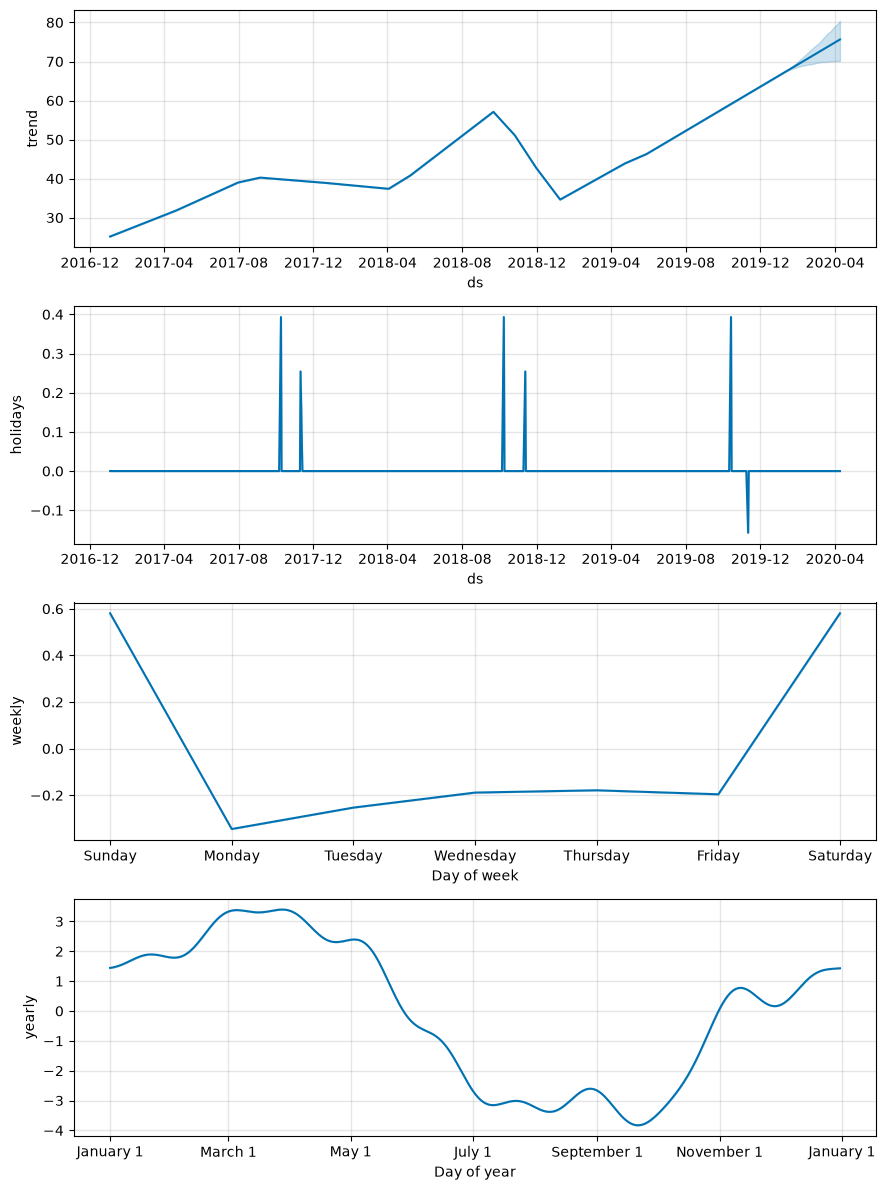

In [ ]:
forecast = m.predict(future)
fig = m.plot_components(forecast)

You can also add manual holidays by providing a `holidays` DataFrame 

In [ ]:
forecast

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,Christmas Day,Christmas Day_lower,Christmas Day_upper,Columbus Day,...,weekly,weekly_lower,weekly_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2017-01-03,25.164699,24.770989,28.057907,25.164699,25.164699,0.0,0.0,0.0,0.0,...,-0.253041,-0.253041,-0.253041,1.467563,1.467563,1.467563,0.0,0.0,0.0,26.379221
1,2017-01-04,25.226244,24.800522,28.088396,25.226244,25.226244,0.0,0.0,0.0,0.0,...,-0.188623,-0.188623,-0.188623,1.484915,1.484915,1.484915,0.0,0.0,0.0,26.522536
2,2017-01-05,25.287789,24.975607,28.262452,25.287789,25.287789,0.0,0.0,0.0,0.0,...,-0.178771,-0.178771,-0.178771,1.505397,1.505397,1.505397,0.0,0.0,0.0,26.614415
3,2017-01-06,25.349334,25.024545,28.201074,25.349334,25.349334,0.0,0.0,0.0,0.0,...,-0.195944,-0.195944,-0.195944,1.528910,1.528910,1.528910,0.0,0.0,0.0,26.682300
4,2017-01-09,25.533969,25.149444,28.469950,25.533969,25.533969,0.0,0.0,0.0,0.0,...,-0.344940,-0.344940,-0.344940,1.614573,1.614573,1.614573,0.0,0.0,0.0,26.803603
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
849,2020-04-05,75.265088,73.603535,83.667522,70.115647,79.689963,0.0,0.0,0.0,0.0,...,0.580659,0.580659,0.580659,3.185338,3.185338,3.185338,0.0,0.0,0.0,79.031085
850,2020-04-06,75.357967,72.976012,83.165177,70.081999,79.852922,0.0,0.0,0.0,0.0,...,-0.344940,-0.344940,-0.344940,3.131172,3.131172,3.131172,0.0,0.0,0.0,78.144199
851,2020-04-07,75.450846,72.556736,83.595197,70.104893,80.031568,0.0,0.0,0.0,0.0,...,-0.253041,-0.253041,-0.253041,3.072228,3.072228,3.072228,0.0,0.0,0.0,78.270033
852,2020-04-08,75.543724,72.979421,83.453563,70.125403,80.225095,0.0,0.0,0.0,0.0,...,-0.188623,-0.188623,-0.188623,3.009375,3.009375,3.009375,0.0,0.0,0.0,78.364477


In [ ]:
# Thanksgiving is the fourth Thursday of November (the stock market is closed that day)
thanksgiving = pd.DataFrame({
  'holiday': 'thanksgiving',
  'ds': pd.to_datetime(['2017-11-23', '2018-11-22', '2019-11-28']),
  'lower_window': 0,
  'upper_window': 1,
})

m = Prophet(holidays=thanksgiving)
#m.add_country_holidays(country_name='US')
m.fit(p_df)

In [ ]:
thanksgiving

,holiday,ds,lower_window,upper_window
0,thanksgiving,2017-11-23,0,1
1,thanksgiving,2018-11-22,0,1
2,thanksgiving,2019-11-28,0,1


Let's check the effect of the holiday in the forecast: Prophet adds a `thanksgiving` column. With `upper_window = 1`, the holiday also covers the next day, the Friday, when the market is open. 

In [ ]:
forecast = m.predict(future)

In [ ]:
forecast[forecast["ds"] == "2017-11-24"][["ds", "thanksgiving"]]

,ds,thanksgiving
226,2017-11-24,-0.292788


In [ ]:
forecast.thanksgiving.value_counts()

thanksgiving
 0.000000    851
-0.292788      3
Name: count, dtype: int64

## Multi-variate forecasting 

Sometimes, you might want to create forecast not only with times but with also other variables. Prophet calls it Regressors. To add a regressor, you can simply do: 

In [ ]:
# Get the data of the Microsoft stock
msft = pd.read_csv("../data/microsoft_stock.csv", index_col="Date", parse_dates=True).loc["2017-01-01":"2020-01-01"]

# Preprocess the data 
msft = pd.DataFrame({
    "ds":msft.index,
    "msft_stock_price": msft["Open"].values
}).reset_index(drop=True)


msft.head()

,ds,msft_stock_price
0,2017-01-03,56.1321
1,2017-01-04,55.8550
2,2017-01-05,55.5958
3,2017-01-06,55.6941
4,2017-01-09,56.1053


Let's incorporate this column in our DataFrame

In [ ]:
p_df["msft_stock_price"] = msft["msft_stock_price"]
p_df.head()

,ds,y,msft_stock_price
0,2017-01-03,26.5975,56.1321
1,2017-01-04,26.6090,55.8550
2,2017-01-05,26.6251,55.5958
3,2017-01-06,26.8226,55.6941
4,2017-01-09,27.0914,56.1053


In [ ]:
m = Prophet()
m.add_regressor('msft_stock_price')

However, once you added a regressor, you absolutely need to have it in your train set AND in your predictions. Therefore, let's split our dataset 

In [ ]:
# Train_test_split 
train_size = int(0.8*len(p_df))


X_train = p_df.iloc[:train_size, :]
X_test = p_df.iloc[train_size:, :]

X_train.head()

,ds,y,msft_stock_price
0,2017-01-03,26.5975,56.1321
1,2017-01-04,26.6090,55.8550
2,2017-01-05,26.6251,55.5958
3,2017-01-06,26.8226,55.6941
4,2017-01-09,27.0914,56.1053


In [ ]:
m.fit(X_train)

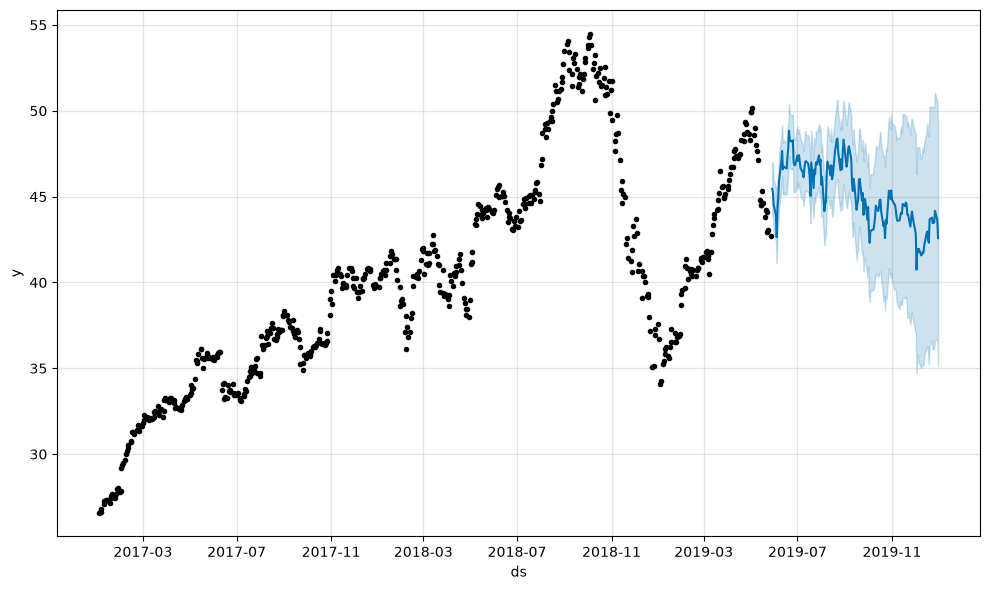

In [ ]:
# Forecast
forecast = m.predict(X_test)

# Viz
fig = m.plot(forecast)

In [ ]:
fig = px.scatter(p_df, x = "ds", y = "y")
fig.add_trace(px.line(forecast, x="ds", y="yhat").data[0])
fig['data'][1]['line']['color']="#4BE8E0"
fig.show()



::: {.callout-warning title="A regressor must be known in the future"}
To forecast, Prophet needs the value of each regressor **for the future dates too**. Here we used the real Microsoft stock price of the test period: in real life, nobody knows it at the time of the forecast, so this score is too optimistic. Good regressors are known in advance: holidays, planned promotions, the weather forecast, the dates of a lockdown once it is announced...
:::



## Resources 

* [Seasonality, Holiday Effects, And Regressors](https://facebook.github.io/prophet/docs/seasonality,_holiday_effects,_and_regressors.html#additional-regressors)
* [Forecasting at Scale](https://peerj.com/preprints/3190/)
* [Introduction to Time Series Analysis](https://www.itl.nist.gov/div898/handbook/pmc/section4/pmc4.htm)
* [Time Series](https://en.wikipedia.org/wiki/Time_series#:~:text=A%20time%20series%20is%20a,sequence%20of%20discrete%2Dtime%20data.)

::: {.sb-next}
**[Your turn: Time series exercises →](../exercises/electricity.ipynb)**
:::